In [2]:
from sklearn.datasets import make_regression

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

In [4]:
X, y = make_regression(
    n_samples=100,
    n_features=1,
    n_informative=1,
    n_targets=1,
    noise=20,
    random_state=13
)

In [5]:
X = X.ravel()


idx = np.argsort(X)
X = X[idx]
y = y[idx]


fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlim(X.min() - 1, X.max() + 1)
ax.set_ylim(y.min() - 10, y.max() + 10)
ax.set_xlabel("X")
ax.set_ylabel("y")
ax.set_title("Animated Regression Dataset")


scatter = ax.scatter([], [], alpha=0.7)

def init():
    scatter.set_offsets(np.empty((0, 2)))
    return (scatter,)

def update(frame):
    points = np.column_stack((X[:frame + 1], y[:frame + 1]))
    scatter.set_offsets(points)
    ax.set_title(f"Animated Regression Dataset — {frame + 1}/{len(X)} points")
    return (scatter,)

anim = FuncAnimation(
    fig,
    update,
    frames=len(X),
    init_func=init,
    interval=50,
    blit=False,
    repeat=False
)


plt.close(fig)
display(HTML(anim.to_jshtml()))

In [32]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X,y)
print(reg.coef_)
print(reg.intercept_)

ValueError: Expected 2D array, got 1D array instead:
array=[-2.18711527 -1.94539068 -1.92415945 -1.63909341 -1.61510796 -1.51284512
 -1.26160595 -1.18541881 -1.12050687 -1.08718159 -1.04537713 -0.98416078
 -0.98027432 -0.92833523 -0.85414295 -0.78898902 -0.77466003 -0.76862702
 -0.76403397 -0.75745323 -0.72099967 -0.71239066 -0.65751727 -0.65105648
 -0.6209797  -0.53032741 -0.52316421 -0.51196509 -0.48137142 -0.45375238
 -0.43714566 -0.42989708 -0.38445769 -0.37591996 -0.37011608 -0.34660679
 -0.33861825 -0.33267578 -0.32212366 -0.31726597 -0.31485808 -0.27813452
 -0.24332625 -0.23242587 -0.2073497  -0.14521133 -0.08165156 -0.05753239
 -0.04450308 -0.02677165 -0.00238903  0.10126979  0.12730328  0.18494595
  0.20780005  0.21745166  0.23785784  0.31735092  0.34875059  0.3595323
  0.39724133  0.45181234  0.45315861  0.45348104  0.46565797  0.49087183
  0.50113729  0.51432886  0.53233789  0.54791831  0.56226171  0.56284679
  0.56465429  0.60628866  0.63988397  0.71097479  0.72196506  0.72

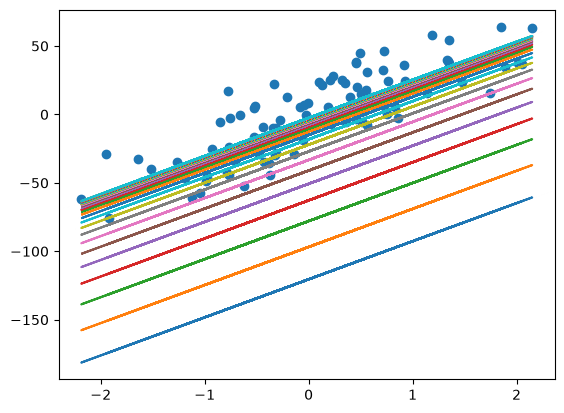

In [10]:
b = -150
m = 27.82
lr = 0.001
all_b = []
all_cost = []

epochs = 30

for i in range(epochs):
    slope = 0
    cost = 0
    for j in range(X.shape[0]):
        slope = slope - 2*(y[j] - (m * X[j]) -  b)
        cost = cost + (y[j] - m * X[j] -b) ** 2

    b = b - (lr * slope)
    all_b.append(b)
    all_cost.append(cost)
    y_pred = m * X + b
    plt.plot(X,y_pred)
plt.scatter(X,y)

In [16]:
all_b = np.array(all_b).ravel()

In [17]:
all_b

array([-120.4588544 ,  -96.82593791,  -77.91960473,  -62.79453818,
        -50.69448494,  -41.01444235,  -33.27040827,  -27.07518102,
        -22.11899921,  -18.15405376,  -14.98209741,  -12.44453232,
        -10.41448025,   -8.7904386 ,   -7.49120528,   -6.45181862,
         -5.62030929,   -4.95510183,   -4.42293586,   -3.99720308,
         -3.65661686,   -3.38414789,   -3.16617271,   -2.99179256,
         -2.85228845,   -2.74068515,   -2.65140252,   -2.57997641,
         -2.52283553,   -2.47712282])

In [18]:
all_cost = np.array(all_cost).ravel()
all_cost

array([2210040.49020261, 1424629.13499295,  921965.86765877,
        600261.37656489,  394370.50226481,  262600.34271276,
        178267.44059944,  124294.38324692,   89751.62654131,
         67644.26224972,   53495.5491031 ,   44440.37268926,
         38645.05978441,   34936.0595253 ,   32562.29935947,
         31043.09285334,   30070.80068942,   29448.5337045 ,
         29050.28283416,   28795.40227714,   28632.27872065,
         28527.87964449,   28461.06423575,   28418.30237416,
         28390.93478274,   28373.41952423,   28362.20975879,
         28355.0355089 ,   28350.44398898,   28347.50541622])

In [25]:
num_epochs = list(range(1,31)) 

In [20]:

fig, ax = plt.subplots(figsize=(9, 5))

# fig.set_tight_layout(True)

x_i = np.arange(-3, 3, 0.1)
y_i = x_i * m - 150

ax.scatter(X, y)
line, = ax.plot(x_i, x_i * 50 - 4, 'r-', linewidth=2)

def update(i):
    label = 'epoch {0}'.format(i + 1)
    line.set_ydata(x_i * m + all_b[i])
    ax.set_xlabel(label)
    return line,

anim = FuncAnimation(
    fig,
    update,
    repeat=True,
    frames=epochs,
    interval=500
)

plt.close(fig)
display(HTML(anim.to_jshtml()))


IndexError: list index out of range

Error in callback <function _draw_all_if_interactive at 0x13150da80> (for post_execute), with arguments args (),kwargs {}:


TypeError: 'int' object is not subscriptable

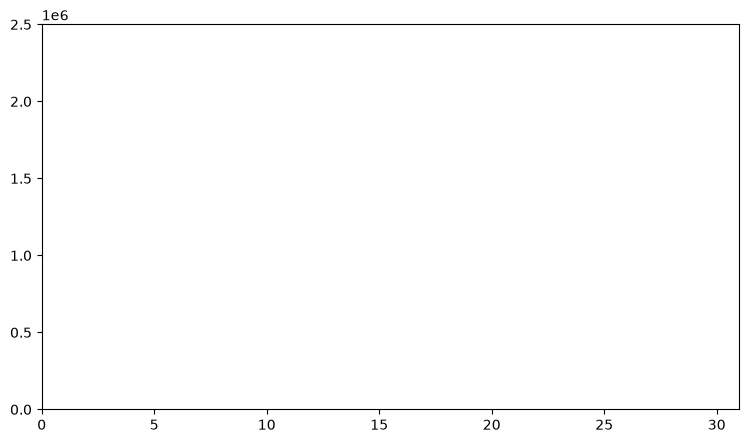

In [23]:

# Creating a blank window for the animation
fig = plt.figure(figsize=(9, 5))
axis = plt.axes(xlim=(0, 31), ylim=(0, 2500000))

line, = axis.plot([], [], lw=2)

xdata, ydata = [], []

# Animation function
def animate(i):
    label = 'epoch {0}'.format(i + 1)
    xdata.append(num_epochs[i])
    ydata.append(all_cost[i])
    line.set_data(xdata, ydata)
    axis.set_xlabel(label)
    return line,

# Calling the animation function
anim = animation.FuncAnimation(
    fig,
    animate,
    frames=30,
    repeat=False,
    interval=500
)

f = r"animation1.gif"
writergif = animation.PillowWriter(fps=2)
anim.save(f, writer=writergif)
